In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA доступна: True
GPU: Tesla T4
CUDA: 13.0


In [ ]:
%pip uninstall -y torchao

In [ ]:
from pathlib import Path

for name in ["lab05_lib.py", "lab06_lib.py"]:
    path = Path("/content") / name
    print(name, "— найден" if path.exists() else "— отсутствует")

lab05_lib.py — найден
lab06_lib.py — найден


In [ ]:
import lab05_lib as L
import lab06_lib as M

print("Загрузка SD Turbo...")
pipe = L.load_pipe()
print("SD Turbo загружена")

print("Загрузка CLIP...")
clip = M.load_clip()
print("CLIP загружен")

print("GPU:", torch.cuda.get_device_name(0))

Загрузка SD Turbo...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

SD Turbo загружена
Загрузка CLIP...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP загружен
GPU: Tesla T4


In [ ]:
N = 22

c = (N - 1) // 6
k = (N - 1) % 6

factor = M.FACTORS[k]
a_cfg, b_cfg = M.settings(factor, c)

print("Вариант:", N)
print("Бриф:", c + 1)
print("Фактор:", factor)

print("\nУсловие A:")
print(a_cfg)

print("\nУсловие B:")
print(b_cfg)

print("\nSeed:", list(M.SEEDS))

Вариант: 22
Бриф: 4
Фактор: prompt_short_to_structured

Условие A:
{'prompt': 'ecology lecture visual, forest', 'steps': 1, 'guidance': 0.0, 'size': 512}

Условие B:
{'prompt': 'visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people', 'steps': 1, 'guidance': 0.0, 'size': 512}

Seed: [101, 102, 103, 104, 105]


In [ ]:
result = M.variant_summary(pipe, clip, n=22)

print("Вариант:", result["variant"])
print("Бриф:", result["ctx"])
print("Фактор:", result["factor"])

print("\nМетрика | Среднее A | SD(A) | Среднее B | Δ(B−A) | |Δ|/SD | >2SD")
for row in result["rows"]:
    print(row)

Вариант: 22
Бриф: 4
Фактор: prompt_short_to_structured

Метрика | Среднее A | SD(A) | Среднее B | Δ(B−A) | |Δ|/SD | >2SD
('clip', 27.325907945632935, 1.0922371967388913, 33.107295632362366, 5.781387686729431, 5.293161324290187, True)
('edge', 0.03317692989466292, 0.005092525876140646, 0.03934468621050201, 0.0061677563158390875, 1.21113892513263, False)
('contrast', 0.15323501292550995, 0.02819489150971871, 0.12241282774229686, -0.030822185183213086, 1.093183322680591, False)
('seconds', 0.28231593659998, 0.004062803006643605, 0.2790066751999348, -0.003309261400045227, 0.8145266690592267, False)


Сохранено: comparison.png
Слева — A (короткий промпт)
Справа — B (структурированный промпт)


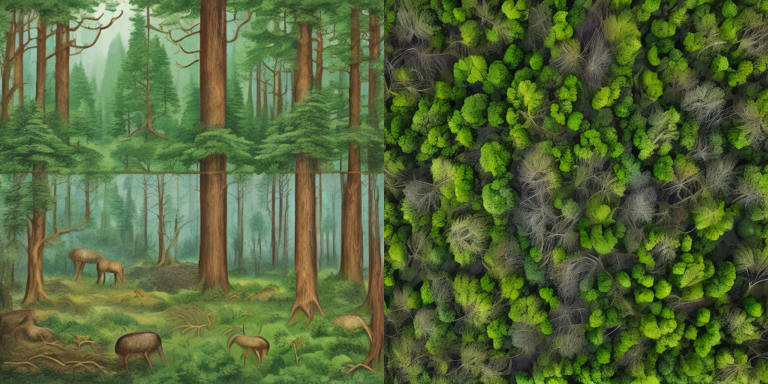

In [ ]:
from PIL import Image
from IPython.display import display

seed = 101

img_a = L.generate(
    pipe,
    a_cfg["prompt"],
    seed,
    steps=a_cfg["steps"],
    guidance=a_cfg["guidance"],
    size=a_cfg["size"]
)[0]

img_b = L.generate(
    pipe,
    b_cfg["prompt"],
    seed,
    steps=b_cfg["steps"],
    guidance=b_cfg["guidance"],
    size=b_cfg["size"]
)[0]

comparison = Image.new("RGB", (768, 384))

comparison.paste(img_a.resize((384, 384)), (0, 0))
comparison.paste(img_b.resize((384, 384)), (384, 0))

comparison.save("comparison.png")

print("Сохранено: comparison.png")
print("Слева — A (короткий промпт)")
print("Справа — B (структурированный промпт)")

display(comparison)

In [ ]:
p = L.BRIEFS[3]

x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]

print(
    "SHA совпали:",
    L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1))
)
print("CFG активен при guidance=1.0:", pipe.do_classifier_free_guidance)

x3 = L.generate(pipe, p, 101, guidance=3.0)[0]

print("CFG активен при guidance=3.0:", pipe.do_classifier_free_guidance)
print("PSNR (0.0 vs 3.0):", L.psnr_db(x0, x3))

SHA совпали: True
CFG активен при guidance=1.0: False
CFG активен при guidance=3.0: True
PSNR (0.0 vs 3.0): 12.490741739416029


In [ ]:
import pandas as pd

columns = [
    "metric",
    "mean_A",
    "sd_A",
    "mean_B",
    "delta_B_minus_A",
    "delta_over_sd",
    "above_2sd"
]

df = pd.DataFrame(result["rows"], columns=columns)

df.to_csv("results.csv", index=False)

display(df.round(5))
print("Сохранено: results.csv")

,metric,mean_A,sd_A,mean_B,delta_B_minus_A,delta_over_sd,above_2sd
0,clip,27.32591,1.09224,33.10730,5.78139,5.29316,True
1,edge,0.03318,0.00509,0.03934,0.00617,1.21114,False
2,contrast,0.15324,0.02819,0.12241,-0.03082,1.09318,False
3,seconds,0.28232,0.00406,0.27901,-0.00331,0.81453,False


Сохранено: results.csv
